# Habitat Analyses with geeo: Worked Examples

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leonsnill/geeo/blob/master/docs/habitat-type-mapping_geeo.ipynb)

This tutorial walks through the three worked examples demonstrating how GEEO can be used in ecological research. The overarching theme of these examples is to illustrate how to generate satellite image features for habitat analyses:

1. **Example 1: Retrieving Habitat Metrics from Multi-Temporal Landsat Imagery** - Replicating and extending the multi-seasonal Spectral-Temporal-Metric (STM) and quality-screening (NVO) workflow of Oeser et al. (2019) using Landsat-8 and -9 data.
2. **Example 2: Equidistant, Interpolated Time Series** - Generating a regular 16-day time series across 15 years (2010–2024) from the Landsat archive and Radial Basis Function convolution.
3. **Example 3: Exporting imagery for a reference land cover survey** - Extracting analysis-ready time series stacks (TSS) at 505,509 pan-European LUCAS survey points, enabling wall-to-wall mapping of land cover.

## 0. Workflow Design & Use

A brief overview of **geeo**'s fundamental workflow design and use.

**geeo** is a processing pipeline and collection of algorithms for obtaining Analysis-Ready-Data (ARD) and higher-level image products from multispectral image archives, primarily the Landsat and Sentinel-2 archives, using the Google Earth Engine Python API. 

*geeo* follows a modular structure, organised along hierarchical processing levels, and corresponding image products (Figure below, left):

- LEVEL-2 (`geeo/level2`): Preprocessed, harmonized, spatio-temporally subsetted surface reflectance time series stacks (TSS) and mosaics (TSM)   
- LEVEL-3 (`geeo/level3`): Advanced spectral features including Spectral-Temporal-Metrics (STM) and Pixel-based Composites (PBC), as well as Time Series Interpolation (TSI)
- LEVEL-4 (`geeo/level4`): Semantic features, i.e. information derived from spectral signals. Currently implemented in this workflow are Land Surface Phenology (LSP) metrics.   
- EXPORT (`geeo/export`): Export module handling metadata and projection settings, and constructing export tasks.

<div>
<img src="https://raw.githubusercontent.com/leonsnill/geeo/develop/geeo/data/fig/geeo_workflow_manuscript.png" width="60%" style="display:block; margin: 0 auto;"/>
</div>

Typically, there is no need to directly interact with the submodules as described above, users simply provide the processing instructions via a parameter .yml-file or python dictionary. The intended approach to using *geeo* is to:

1. **Create a .yml parameter file** from an existing blueprint using the `create_parameter_file()` function
2. **Adjust the parameter settings** in the .yml file to your requirements
3. **Run the adjusted parameter file** using `run_param()` to trigger the processing (and export)

Users can use *geeo* also "interactively" and/or within their own workflows by simply accessing the returned dictionary (and containing data) after *geeo* processed the instructions.

## 1. Setup & Environment

This tutorial assumes that you have already installed GEEO and authenticated your Google Earth Engine session. For installation instructions and an overview of the core architecture, please refer to the introductory tutorial (	utorial_0_introducing-geeo.ipynb) and the [GEEO GitHub repository](https://github.com/leonsnill/geeo).

We begin by importing the required packages:

In [1]:
my_project_name = 'eexnill'  # change this to your Google Cloud project name that has access to Earth Engine

# earth engine python API
import ee
ee.Authenticate()
ee.Initialize(project=my_project_name)
# eerepr adds an interactive html representation of Earth Engine objects in Jupyter notebooks
import eerepr
eerepr.initialize()
# geemap allows interactive mapping with Earth Engine in Python
import geemap

# GEEO
try:  # if geeo is already installed in environment
    import geeo
except:   # not installed, install it
    !pip install --quiet git+https://github.com/leonsnill/geeo.git
    import geeo

> **Note on interactive execution:** In the code cells below, large export tasks (EXPORT_IMAGE: False, EXPORT_TABLE: False) are disabled by default to avoid triggering long-running server exports during tutorial runs. Precomputed products and visualisations are loaded from precomputed Earth Engine assets so you can inspect the outputs immediately and we avoid unnecessary ressource use.

## 2. Study Area & Spatial Extent

Our primary study area is a 150 × 150 km region at the French-Italian border of the southwestern Alps. Spanning an elevation gradient from lowland valleys to high-alpine peaks, it encompasses diverse biome types including temperate deciduous and coniferous forests, Mediterranean shrublands, and alpine grasslands.

**geeo** provides the helper function create_roi() to convert local vector files (e.g. GeoPackage, Shapefile, GeoJSON) into server-side Earth Engine objects with consistent spatial metadata:

In [2]:
study_area = 'https://raw.githubusercontent.com/leonsnill/geeo/master/geeo/data/GLANCE_EU_150-X029-Y029.gpkg'  # the study area is saved in GEEO's GitHub repo
roi = geeo.create_roi(study_area)  # returns a dictionary of various formats, including an ee.Geometry
roi.keys()

c:\Users\leonx\miniconda3\envs\earth\Lib\site-packages\pyogrio\core.py:38: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


dict_keys(['roi_geom', 'roi_featcol', 'roi_bbox', 'roi_gdf'])

create_roi() returns a dictionary containing the spatial region represented in several formats:
- roi_geom: An [ee.Geometry](https://developers.google.com/earth-engine/guides/geometries) representing the polygon boundary.
- roi_featcol: An [ee.FeatureCollection](https://developers.google.com/earth-engine/guides/feature_collections) wrapping the geometry with metadata.
- roi_bbox: An ee.Geometry bounding box of the spatial extent.
- roi_gdf: A local GeoPandas [GeoDataFrame](https://geopandas.org/en/stable/docs/reference/geodataframe.html).


The ee.FeatureCollection defines the 150 × 150 km bounding tile used for the processing workflows below. We visualise the study area extent using geemap:

In [3]:
roi_featcol = roi['roi_featcol']  # extract the ee.FeatureCollection

M = geemap.Map(center=[44, 7], zoom=7)
M.add_basemap('HYBRID')
vis_params = {'color': 'red', 'width': 2, 'lineType': 'solid','fillColor': '00000000'}
M.addLayer(roi_featcol.style(**vis_params), {}, 'Study Area')
M

Map(center=[44, 7], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', trans…

---

## Example 1: Retrieving Habitat Metrics from Multi-Temporal Landsat Imagery

Multispectral satellite time series capture vegetation productivity, moisture dynamics, and phenological seasonality - usefull predictors for species distribution models (SDMs) and habitat suitability assessments. Widely used frameworks, such as the Dynamic Habitat Indices (DHIs; Radeloff et al., 2019; Razenkova et al., 2025) and multitemporal habitat metrics (Oeser et al., 2019), characterise habitat conditions using intra-annual observations of remotely sensed indicators.

In remote sensing, these metrics are derived as **Spectral Temporal Metrics (STMs)**. Spectral Temporal Metrics are summary statistics (percentiles, mean, standard deviation) across valid observations for defined temporal intervals. Spectral Temporal Metrics serve two purposes:
1. **Dimensionality reduction:** They condense multi-year, high-dimensional observation stacks into a compact set of ecologically meaningful predictors representing median conditions, variability, and extremes.
2. **Gap handling:** Optical satellite observations are regularly obscured by clouds, shadows, and snow. By aggregating over temporal windows, Spectral Temporal Metrics bridge quality-masked gaps to deliver continuous, wall-to-wall feature surfaces.

### Workflow Alignment with Oeser et al. (2019)
Following the methodology of Oeser et al. (2019) for wildlife habitat mapping, we configure *geeo* to derive multi-seasonal metrics across our Alpine study area:
- **Sensor archive:** Landsat 8 and Landsat 9 Collection 2 Level-2 surface reflectance, screened for clear observations (< 75% scene cloud cover, cloud and shadow masking via QA bands).
- **Target period:** Three-year baseline (2022–2024).
- **Temporal folding:** Four seasons—Spring (March–May), Summer (June–August), Autumn (September–November), and Winter (December–February).
- **Spectral indices:** Tasseled Cap Greenness (TCG; photosynthetic activity), Brightness (TCB; bare soil / openness), and Wetness (TCW; vegetation and soil moisture).
- **Reducers:** 10th percentile (p10), median (p50), 90th percentile (p90), and standard deviation (stdDev).
- **Quality screening:** Number of Valid Observations (NVO), tracking clear-pixel availability across each season to evaluate metric reliability.

### Specifying Processing Settings

As described above (0. Workflow Design & Use), workflows in *geeo* are parameterised either through a YAML configuration file or directly through Python dictionaries. We have parameterised the file [example-1_habitat-metrics.yml](habitat-type-mapping\example-1_habitat-metrics.yml) to contain the desired processing settings from the above list. You can inspect the file to get familiar with the parameters. We provide an extensive overview for all parameters in the [Documentation](../documentation.md), but for now, we focus on the paramaters required for this example.

To give you an overview of the adjusted parameters, we can print the parameters:

In [4]:
# load parameters from the .yml file into a dictionary
prm_habitat_metrics = geeo.load_parameters('https://raw.githubusercontent.com/leonsnill/geeo/develop/docs/tutorials/habitat-type-mapping/example-1_habitat-metrics.yml')

# we will print the parameters and associated values for illustration
new_parameters_of_interest = [
    'YEAR_MIN', 
    'YEAR_MAX',
    'MONTH_MIN',
    'MONTH_MAX',
    'ROI',
    'SENSORS',
    'MAX_CLOUD', 
    'MASKS_LANDSAT',
    'FEATURES',
    'FOLD_CUSTOM',
    'NVO',
    'NVO_FOLDING',
    'STM',
    'STM_BASE_IMGCOL',
    'STM_FOLDING'
]

for p in new_parameters_of_interest:
    print(f"{p}: {prm_habitat_metrics[p]}")

YEAR_MIN: 2022
YEAR_MAX: 2024
MONTH_MIN: 1
MONTH_MAX: 12
ROI: [6.26, 44.35, 6.57, 44.58]
SENSORS: ['L9', 'L8']
MAX_CLOUD: 75
MASKS_LANDSAT: ['cloud', 'cshadow', 'fill', 'dilated']
FEATURES: ['TCG', 'TCB', 'TCW']
FOLD_CUSTOM: {'year': None, 'month': ['3-5', '6-8', '9-11', '12-2'], 'doy': None, 'date': None}
NVO: True
NVO_FOLDING: True
STM: ['p10', 'p50', 'p90', 'stdDev']
STM_BASE_IMGCOL: TSS
STM_FOLDING: True


Alternatively, we could specify the settings directly in a python dictionary, but this requires being familiar with *geeo* and its parameters, so that the parameter file approach is the easiest and intended way to instruct *geeo*. For completeness, this would look as follows:

In [5]:
prm_habitat_metrics = {
    'YEAR_MIN': 2022,
    'YEAR_MAX': 2024,
    'MONTH_MIN': 1,                                 # we include all months at first, the seasonal subwindows are defined in the folding section
    'MONTH_MAX': 12,
    'ROI': [6.26, 44.35, 6.57, 44.58],              # note that we defined a smaller ROI than "study area" in case exporting is triggered to avoid unnecessary ressource use!
    'SENSORS': ['L8', 'L9'],                        # Landsat-8 and Landsat-9 Collection 2 Tier 1 surface reflectance data
    'MAX_CLOUD': 75,                                # only include scenes with less or equal 75% cloud cover
    'MASKS_LANDSAT': [                              # mask all pixels of this kind
        'cloud', 'cshadow', 
        'fill', 'dilated'
        ],
    'FEATURES': ['TCG', 'TCB', 'TCW'],              # Tasseled Cap greenness, brightness, and wetness
    'FOLD_CUSTOM': {                                # Temporal folding allows to calculate habitat metrics for custom time windows, e.g. month ranges
        'month': ['3-5', '6-8', '9-11', '12-2'],    # instead, we want a custom range of months
        },
    'NVO': True,                                    # Number of Valid Observations (NVO) is a quality metric that measures data availability for each pixel over time
    'NVO_FOLDING': True,                            # we want to calculate the quality layer for each of the custom time windows defined in the folding section
    'STM': ['p10', 'p50', 'p90', 'stdDev'],         # statistical metrics/reducers: 10th, 50th, 90th percentiles, and the standard deviation
    'STM_BASE_IMGCOL': 'TSS',                       # collection on which to calculate the STMs; here we use the basic Time-Series-Stack (TSS)
    'STM_FOLDING': True,                            # actually apply the custom folding settings when calculating the STMs
}

> **Note:** Using YAML parameter files is generally recommended as it separates configuration from code and ensures reproducibility. Here we use an in-line dictionary to make every setting explicit within the notebook.

### Executing the Pipeline with run_param()

Once we have the settings in place, we can run the processing using the `run_param()` function:

In [6]:
run_habitat_metrics = geeo.run_param(prm_habitat_metrics)

As described above (0. Workflow Desing & Use), `run_param` is a wrapper function that executes the entire chain of `run_level2()` -> `run_level3()` -> `run_level4` -> `run_export()`. Each module receives the parameter dictionary, validates the parameters, attaches the resulting Earth Engine objects (e.g. ee.ImageCollection), and passes the enriched dictionary to the subsequent step. Our variable `run_habitat_metrics` contains the full execution and results of the pipeline, i.e. user-defined parameters merged with geeo's system defaults (parameters not explicitly modified by the user), alongside references to the processed server-side images / collections.

Key outputs in our example are:

- Time Series Stack (`TSS`): The analysis-ready stack of imagery over time (Level-2)
- Spectral Temporal Metrics (`STM`): The image collection containing the metrics for each of our seasonal time windows (Level-3)
- Number of Valid Obersvations (`NVO`): The image containing four bands with the valid pixel count for each of our seasonal time window (Level-3)

### Inspecting the Products (STMs and NVO)

The 'STM' key holds an ee.ImageCollection containing one multi-band ee.Image for each of the four seasonal windows:

In [7]:
STM = run_habitat_metrics['STM']  # the calculated metrics are stored in an ee.ImageCollection at the STM key
STM  # print STM ee.ImageCollection object and inspect its properties

Expanding the ee.ImageCollection in the Earth Engine representation widget reveals:
- **4 Images:** Corresponding to the four defined seasonal folds.
- **12 Bands per Image:** 3 spectral indices (TCG, TCB, TCW) $\times$ 4 statistical reducers (p10, p50, p90, stdDev).
- **Standardised Temporal Metadata:** Each image's system:index explicitly documents the temporal aggregation window (e.g., Y2022-2024_M03-05_D001-366). When exporting, GEEO automatically embeds these temporal identifiers into band names and output filenames.

### Configuring Export Settings & Asset Retrieval

Exporting raster collections in Earth Engine requires setting Coordinate Reference Systems (CRS), spatial bounds, and pixel resolutions. Unspecified metadata can lead to unintended grid offsets and reprojection artifacts.

**geeo** facilitates exact spatial extent and pixel alignment via exlicitly defining the CRS transform and image dimensions instead of relying on Earth Engine to figure this out based on fewer implicit settings (usually users only set a 'scale', i.e. pixel grain size and 'region', i.e. a study area extent). geeo also allows to use predefined (continental) gridding schemes such as the GLANCE continental projection system.

Key parameters for our export to the desired study area are:
- CRS: Target coordinate system ('EU' for European LAEA projection from the GLANCE system).
- SCALE: 30 m spatial resolution matching Landsat ground sampling distance.
- RESAMPLING: Bilinear interpolation for continuous spectral data.
- DATA_TYPE: 16-bit signed integer (int16) with a scale factor of 10,000 to efficiently store the data, with no-data values assigned to -9999.
- EXPORT_LOCATION: Target destination ('Asset' or 'Drive').

In [8]:
habitat_metric_settings_export = {
    'PIX_RES': 30,  # spatial resolution
    'CRS': 'EU',  # EU: Europe glance (https://measures-glance.github.io/glance-grids/)
    'RESAMPLING_METHOD': 'bilinear',  # bilinear resampling for continuous data
    'DATATYPE': 'int16',  # output data type ...
    'DATATYPE_SCALE': 10000,   # ... and scale factor to convert to integer
    'NODATA_VALUE': -9999,  # output nodata value
    'EXPORT_IMAGE': False,  # whether to export the images: setting to true would trigger the export
    'EXPORT_STM': True,  # whether to export the calculated STMs
    'EXPORT_NVO': True,  # whether to export the calculated NVOs
    'EXPORT_LOCATION': 'Asset',  # 'Drive' or 'Asset'
    'EXPORT_DIRECTORY': 'projects/eexnill/assets/geeo_public',  # path to export location
    'EXPORT_DESC': 'HABITAT_METRICS'  # description appended to each image name
}

prm_habitat_metrics.update(habitat_metric_settings_export)

run_habitat_metrics = geeo.run_param(prm_habitat_metrics)  # !!! note that EXPORT_IMAGE is intentionally set to False above here to not trigger unintended exports

> **Note:** EXPORT_IMAGE is set to False above to avoid triggering duplicate export tasks. The exported asset from this run has been precomputed and made publicly accessible for inspection below.

### Visualizing the Products (STMs and NVO)

Once the export task completes on Earth Engine, the multi-band Spectral Temporal Metric is stored under the specified asset path (projects/eexnill/assets/geeo_public/STM_HABITAT_METRICS_2022-2024_LSAT). We can load and inspect the asset:

In [9]:
img_habitat = ee.Image('projects/eexnill/assets/geeo_public/STM_HABITAT_METRICS_2022-2024_LSAT')
print(img_habitat.bandNames().getInfo()[:5])  # print the first 5 band names

['Y2022-2024_M03-05_D001-366_TCG_p10', 'Y2022-2024_M03-05_D001-366_TCG_p50', 'Y2022-2024_M03-05_D001-366_TCG_p90', 'Y2022-2024_M03-05_D001-366_TCG_stdDev', 'Y2022-2024_M03-05_D001-366_TCB_p10']


We visualise the exported STM asset with geemap:

In [10]:
M = geemap.Map(center=[44.25, 7], zoom=8)
M.add_basemap('HYBRID')
selected_bands = [
    'Y2022-2024_M06-08_D001-366_TCB_p50',
    'Y2022-2024_M06-08_D001-366_TCG_p50',
    'Y2022-2024_M06-08_D001-366_TCW_p50'
]
M.addLayer(img_habitat, {'bands': selected_bands, 'min': [1000, 0, -2000], 'max': [6000, 3000, 0]}, 'Summer median STM')
M.addLayer(roi_featcol.style(**vis_params), {}, 'Study Area')
M

Map(center=[44.25, 7], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tr…

Second, we add the Number of Valid Observations (NVO) layer () that allows us to assess the underlying data availability per pixel for the given time windows and thus serves as an important layer for checking the robustness and reliability of our image products:

In [11]:
img_nvo = ee.Image('projects/eexnill/assets/geeo_public/NVO_HABITAT_METRICS_2022-2024_LSAT')
print(img_nvo.bandNames().getInfo())  # print the first 5 band names

['Y2022-2024_M03-05_D001-366_NVO', 'Y2022-2024_M06-08_D001-366_NVO', 'Y2022-2024_M09-11_D001-366_NVO', 'Y2022-2024_M12-02_D001-366_NVO']


In [12]:
M.addLayer(img_nvo.select([1]), {'min': 2, 'max': 50, 'palette': 'gnuplot2'}, 'Number of Valid Observations (NVO) for summer 2022-2024')
M

Map(center=[44.25, 7], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tr…

---

## Example 2: Equidistant, Interpolated Time Series

### Background: Time-Series Interpolation & Daily Mosaicking

While seasonal STMs provide static temporal aggregates, many ecological investigations require dynamic time series. Many applications use interpolated spectral time series, including, for example, assessments of land-use intensity (Rufin et al., 2019), characterisiation of land surface phenology (Kowalski et al., 2020), or for differentiating phenologically complex vegetation types such as in heterogenous savanna ecosystems (Harkort et al. 2025). 

However, observation intervals vary due to factors including satellite orbits and cloud cover, hence optical archives (Landsat and Sentinel-2) are irregular: To resolve this, **Time Series Interpolation (TSI)** reconstructs an equidistant, (potentially) gap-free time series by convolving irregular observations over moving temporal windows.

#### Radial Basis Function (RBF) Convolution
*geeo* implements convolution-based temporal interpolation using Gaussian Radial Basis Functions (RBF). Rather than fitting rigid parametric curve models (e.g., asymmetric double logistics), RBF interpolation evaluates a moving Gaussian kernel across target timestamps:

$$
\hat{y}(t_0) = \frac{\sum_{i=1}^{N} w_i y_i}{\sum_{i=1}^{N} w_i}
$$

where:
- $\hat{y}(t_0)$ is the interpolated value at target time $t_0$.
- $y_i$ is the observed value (e.g., surface reflectance or index) at time $t_i$.
- $N$ is the number of observations within the temporal window.
- $\sum_{i=1}^{N} w_i$ normalizes the sum so the weights sum to 1.
- $w_i$ is the Gaussian weight assigned to observation $i$:

$$
w_i = \exp\left(-\frac{(t_i - t_0)^2}{2\sigma_t^2}\right)
$$

where:
- $w_i$ is the weight assigned to observation $i$.
- $t_i$ is the acquisition time of observation $i$.
- $t_0$ is the target interpolation time.
- $\sigma_t$ is the temporal standard deviation (bandwidth) controlling how rapidly the weights decay with temporal distance.

#### Resolving Data Density Variations with Multi-Kernel Weighting
A single kernel with a narrow width ($\sigma = 16\text{ days}$) accurately tracks rapid phenological transitions during data-dense periods, but can result in gaps during extended nodata periods. Conversely, a wide kernel smoothes persistent gaps but can also oversmooth actual observations and true dynamics. 

*geeo* addresses this trade-off by offering the methods detailed in Schwieder et al. (2016) and Frantz (2019):
- **1RBF**: Single Gaussian kernel with user-defined standard deviation ($\sigma_1$) and search window ($\text{WIN}_1$).
- **2RBF / 3RBF**: Dual- or triple-kernel interpolation. Here, narrow kernels are prioritised when valid observations are abundant (controlled by threshold $\text{BW}_1$), while wider fallback kernels activate automatically when data availability drops.

### Parameterising 1RBF Interpolation

In this example, we generate an equidistant 16-day NDVI time series across 15 years (2010–2024) for the 150 × 150 km Alpine study area using the combined Landsat 7, 8, and 9 archives.

We load the parameters from the parameter file (example-2_time-series-interpolation.yml) using geeo.read_param():

In [13]:
# load parameters from the .yml file into a dictionary
prm_tsi = geeo.load_parameters('https://raw.githubusercontent.com/leonsnill/geeo/develop/docs/tutorials/habitat-type-mapping/example-2_time-series-interpolation.yml')

# we will print the parameters and associated values for illustration
new_parameters_of_interest = [
    'TSI',
    'TSI_BASE_IMGCOL',
    'INTERVAL',
    'INTERVAL_UNIT',
    'INIT_JANUARY_1ST',
    'SIGMA1',
    'WIN1',
]

for p in new_parameters_of_interest:
    print(f"{p}: {prm_tsi[p]}")

TSI: 1RBF
TSI_BASE_IMGCOL: TSM
INTERVAL: 16
INTERVAL_UNIT: day
INIT_JANUARY_1ST: True
SIGMA1: 16
WIN1: 64


The loaded configuration parameters specify:
- **Sensors:** Combined Landsat constellation (SENSORS: ['L9', 'L8', 'L7']) spanning 2010 to 2024.
- **Base Collection:** Time Series Mosaic (TSM) (TSI_BASE_IMGCOL: 'TSM') to consolidate overlapping same-day acquisitions into single daily observations.
- **Interpolation Scheme:** Single Gaussian kernel (TSI: '1RBF') with a standard deviation of 16 days (SIGMA1: 16) and an inclusion half-window of 64 days (WIN1: 64).
- **Temporal Grid:** 16-day intervals (INTERVAL: 16, INTERVAL_UNIT: 'day') anchored to January 1st (INIT_JANUARY_1ST: True).
- **Spectral Target:** Normalized Difference Vegetation Index (FEATURES: ['NDVI']).

### Evaluating Interpolated Time Series at Reference Sites

To assess how well the 1RBF interpolation captures true vegetation dynamics and suppresses residual noise, we evaluate the resulting time series at two contrasting ecological reference sites within the study area:
1. **Alpine Grassland:** Characterised by prolonged winter snow cover (near-zero NDVI) followed by a sharp summer green-up peak.
2. **Subalpine Forest–Grassland Ecotone:** Characterised by higher baseline NDVI with moderate seasonal amplitude.

#### Site A: Alpine Grassland

Interpolating DF ...


100%|██████████| 1/1 [00:00<00:00, 572.60it/s]


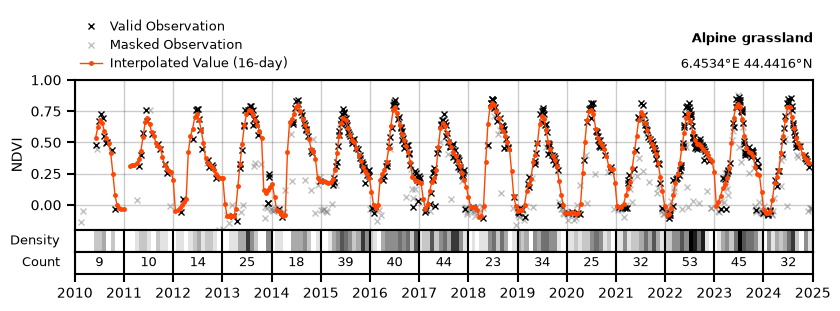

In [14]:
from geeo import plot_tsi

alpine_grassland = [6.453384, 44.44164]
forest_grassland_ecotone = [6.460557, 44.428797]

fig, ax = plot_tsi(prm_tsi, roi=alpine_grassland, feature='NDVI', show_masked=True, figsize=(9, 3),
                              color='orangered', title='Alpine grassland', ylim=[-0.2, 1])

#### Site B: Subalpine Forest–Grassland Ecotone

Interpolating DF ...


100%|██████████| 1/1 [00:00<00:00, 503.58it/s]


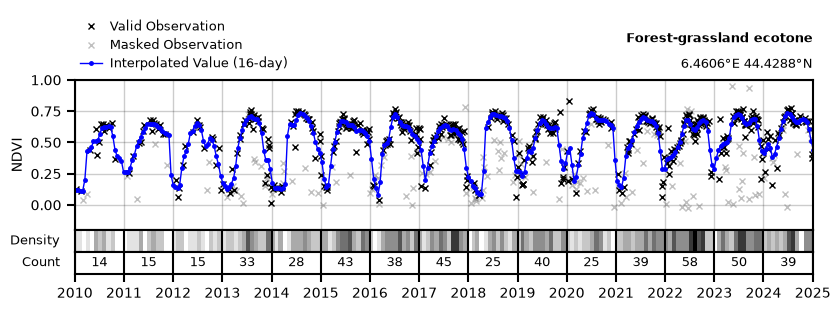

In [15]:
fig, ax = plot_tsi(prm_tsi, roi=forest_grassland_ecotone, feature='NDVI', show_masked=True, figsize=(9, 3),
                              color='blue', title='Forest-grassland ecotone', ylim=[-0.2, 1])

### Running the Interpolation Pipeline

We pass this configuration to geeo.run_param(). As before, EXPORT_IMAGE is set to False in the snippet below to avoid triggering server tasks; the resulting asset has been precomputed for evaluation:

In [16]:
my_run = geeo.run_param(prm_tsi)  # runs the analysis as specified in the .yml file

---------------------------------------------------------
        Exporting Time-Series-Interpolation (TSI)

->  TSI_HABITAT_EU_150-X029-Y029_2010-2024_LSAT_NDVI

---------------------------------------------------------


Once processed and exported, the 15-year interpolated multi-band NDVI asset is available in Earth Engine:

In [17]:
tsi_ndvi = ee.Image('projects/eexnill/assets/geeo_public/landsat-tsi/TSI_HABITAT_EU_150-X029-Y029_2010-2024_LSAT_NDVI')

Inspecting the band names confirms the regular 16-day spacing from 2010 to 2024:

In [18]:
tsi_ndvi.bandNames()

In [19]:
# visualize TSI
example_point = ee.Geometry.Point([6.453384, 44.44164])

M = geemap.Map(center=[44.25, 7], zoom=8)
M.add_basemap('HYBRID')
selected_bands = ['NDVI_20240328', 'NDVI_20240616', 'NDVI_20240904']
M.addLayer(tsi_ndvi, {'bands': selected_bands, 'min': 0, 'max': 8000}, 'TSI NDVI')
M.addLayer(example_point, {'color': 'red'}, 'Example Point')
M.addLayer(roi_featcol.style(**vis_params), {}, 'Study Area')
M

Map(center=[44.25, 7], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tr…

---

## Example 3: Extracting Reference Point Time Series & Combining Server-Side with Local Analysis

In this example we want to showcase how users can export image products for geospatial reference locations to a table format. Specifically, we illustrate this in the context of large-area land cover mapping analogously to the methodology described by Pflugmacher et al., (2019). In their paper, the authors use the LUCAS 'Land use and land cover' survey reference dataset in combination with multispectral Landsat-8 data to map pan-European land cover for the year 2015. More generally, many analyses in ecological / biogeographic modelling, including habitat mapping and species distribution modelling, generally only require obtaining data for available reference points (e.g. occurrence records) for model parameterisation and/or validation instead of creating area-wide predictor imagery. Only after the models have been build and evaluated, users "know" which image features they actually need to map their target. By only obtaining the relevant data at first instead of calculating and downloading all possibly relevant imagery a priori to modelling, users save (often substantial) computational and storage resources. Additionaly, server-side memory limits and execution timeouts in Earth Engine often also require the users to process data more efficiently, e.g. by using spatial tiling and temporal filtering. 

This example primarily illustrates how to obtain image data for reference points in table format, but we cover the whole workflow of:


predicting 12 land-cover classes across a 600 × 600 km tile (EU_600-X007-Y007) in the European Alps.

### Step 1: Server-Side Point Extraction of Landsat ARD (TSS)

The **Land Use/Cover Area frame Survey (LUCAS)** provides in situ field observations across European Union member states. We utilize the harmonized LUCAS dataset compiled by d'Andrimont et al. (2020), which standardizes surveys from 2006 to 2018 into a unified classification scheme. Following Pflugmacher et al. (2019), we group observations into 12 land cover classes:

| Main Class | Description |
| :--- | :--- |
| **Artificial land** | Impervious surfaces (buildings, roads, artificial structures). |
| **Cropland, seasonal** | Annual arable crops (cereals, root crops, vegetables, fodder). |
| **Cropland, perennial** | Permanent woody crops (orchards, vineyards, olive groves). |
| **Forest, broadleaved** | Woodland with $\ge 75\%$ broadleaved canopy cover ($\ge 10\%$ total cover). |
| **Forest, coniferous** | Woodland with $\ge 75\%$ coniferous canopy cover ($\ge 10\%$ total cover). |
| **Forest, mixed** | Mixed tree canopy ($> 25\%$ of each broadleaved and coniferous). |
| **Shrubland** | Vegetation dominated by shrubs and dwarf woody plants. |
| **Grassland** | Natural and managed pastures, meadows, and herbaceous cover. |
| **Barren** | Bare soil, exposed rock, scree, and sparsely vegetated land. |
| **Wetland** | Inland and coastal peatlands, marshes, and bogs. |
| **Water** | Inland water bodies, rivers, lakes, and reservoirs. |
| **Snow/ice** | Glaciers and perennial snow fields. |

A harmonized version of LUCAS (d'Andrimont et al., 2020) covering field surveys from 2006 to 2018 is [available in Earth Engine](https://developers.google.com/earth-engine/datasets/catalog/JRC_LUCAS_HARMO_THLOC_V1#description). **We processed this ee.FeatureCollection to match the pre-processing and categorization described in Pflugmacher et al. (2019) and uploaded the resulting ee.FeatureCollection to a publicly accessible Asset (`projects/eexnill/assets/geeo_public/LUCAS_HARMO_V1_EO_LC`).** The script to reproduce the dataset is provided as separate Python file [LUCAS_1_preprocess.py](habitat-type-mapping/LUCAS_1_preprocess.py)

The standardized reference points (505,509 observations across Europe) were ingested into Earth Engine (projects/eexnill/assets/geeo_public/LUCAS_HARMO_V1_EO_LC):

In [20]:
lucas = ee.FeatureCollection('projects/eexnill/assets/geeo_public/LUCAS_HARMO_V1_EO_LC')
lucas.size()

We display the pan-European point distribution:

In [21]:
# names for legend
lc_names = [
    "Artificial land",
    "Cropland, seasonal",
    "Cropland, perennial",
    "Forest, broadleaved",
    "Forest, coniferous",
    "Forest, mixed",
    "Shrubland",
    "Grassland",
    "Barren",
    "Wetland",
    "Water",
    "Snow/ice"
]
# colours for classes
lc_colors = [
    "FF0000",  # 0 - Artificial land (red)
    "FFD700",  # 1 - Cropland, seasonal (golden/yellow)
    "CD853F",  # 2 - Cropland, perennial (tan/brown)
    "32CD32",  # 3 - Forest, broadleaved (forest green)
    "006400",  # 4 - Forest, coniferous (dark green)
    "228B22",  # 5 - Forest, mixed (lime green)
    "FFA500",  # 6 - Shrubland (orange/kaki)
    "9ACD32",  # 7 - Grassland (yellow green)
    "D2B48C",  # 8 - Barren (tan)
    "800080",  # 9 - Wetland (purple)
    "0000FF",  # 10 - Water (blue)
    "FFFFFF"   # 11 - Snow/ice (white)
]

styled_lucas = geemap.ee_vector_style(
    lucas, 
    column="LC_ID", 
    labels=list(range(len(lc_names))), 
    color=lc_colors,
    pointSize=1
)

M = geemap.Map(center=[44, 7], zoom=6)
M.add_basemap('HYBRID')
M.addLayer(styled_lucas, {}, "lc1")
M.add_legend(title="Land Cover Classes", keys=[str(l) for l in lc_names], colors=lc_colors)
M

Map(center=[44, 7], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', trans…

### Step 2: Exporting Time Series Stack Image Data for LUCAS Reference Points

The key step we want to highlight in this example is how users can use *geeo*'s tiling function to request exports in spatial tiles (i.e. subsets). When exporting imagery or tables, it is often usefull to organise the data according to a spatial tiling scheme. 

#### Spatial Tiling
**geeo has in-built functions for creating a spatial tiling scheme for a given CRS.** This faciliates spatial organization of the data similar to the datacube concept and allows precisely aligning output images onto a grid scheme. Especially when working with long and/or dense time series, as well as when working with different geospatial raster datasets in a given region, spatial tiling schemes can be extremely usefull.

- **Grid:** The spatial, regular division of the space into tiles starting the grid origin.
- **Grid Origin:** Upper left corner coordinate where numbering of tiles start in X and Y direction
- **Tile:** A (square) grid cell covering an area defined by the tile size. Associated with a unique identifier (X000_Y0000).
- **Tile Size:** The n times n size in meters covered by a tile.

<div>
<img src="https://raw.githubusercontent.com/leonsnill/geeo/master/geeo/data/fig/datacube.svg" width="40%" style="display:block; margin: 0 auto;"/>
</div>

#### Modified Global LANd Cover mapping and Estimation (GLANCE) Grids

**Geeo contains a modified version of the Global LANd Cover mapping and Estimation (GLANCE) projection and tiling system** (https://github.com/measures-glance/glance-grids). 
GLANCE grids is a tile gridding system that uses Lambert Azimuthal Equal Area projections for different 'continents' to minimize distortion for each region. Originally, the grid system is based on a 30m pixel and with tiles that are 5000x5000 pixels in size, i.e. 150x150km tiles. Geeo allows to specify other tile sizes that all cover the common pixel sizes of medium resolution satellite data (10m, 20m, 30m). 

<br>

<div style="text-align:center;">
    <img src="https://raw.githubusercontent.com/leonsnill/geeo/master/geeo/data/GLANCE-tiles/glance_continents_overview.png" width="40%"/>
    <p><em>Figure: GLANCE grids overview (source: https://measures-glance.github.io/glance-grids/)</em></p>
</div>


For illustrational purposes, we can create a 300 x 300 km GLANCE tiling scheme for Europe as follows:

In [22]:
glance_eu = geeo.create_glance_tiles(continent_code='EU', tile_size=300000, land_mask=True)

M.add_gdf(glance_eu, style={'color': 'red'}, layer_name="EU Glance", zoom_to_layer=False)
M

Filtering grid tiles using the land mask...


Map(center=[44, 7], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', trans…

When exporting imagery or tables, we can directly specify in the parameter file that we wish to organise the export according to a specified tiling scheme. The parameter `ROI_TILES` allows us to to specify the tiling either based on the `ROI` provided, using the GLANCE scheme, or an additional geospatial dataset (local or server-side ee.FeatureCollection).

For our specific example, in order to export Landsat 7, 8, and 9 Level-2 Time Series Stack (TSS) data at all 505,509 reference points for 2014–2019, we specify the `LUCAS_HARMO_V1_EO_LC` as `ROI` and set `ROI_TILES: EU_300`. The full parameter specification then looks as follows:

In [23]:
# load parameters from the .yml file into a dictionary
#prm_habitat_metrics = geeo.load_parameters('https://raw.githubusercontent.com/leonsnill/geeo/develop/docs/tutorials/habitat-type-mapping/example-3_reference-data-to-table.yml')
prm_reference_data_to_table = geeo.load_parameters('habitat-type-mapping/example-3_reference-data-to-table.yml')

# we will print the parameters and associated values for illustration
new_parameters_of_interest = [
    'YEAR_MIN', 
    'YEAR_MAX',
    'ROI',
    'ROI_TILES',
    'SENSORS',
    'FEATURES',
    'EXPORT_TABLE',
    'EXPORT_TSS',
    'EXPORT_DESC',
    'EXPORT_TABLE_TILE_SCALE'  # this is set to 16 to avoid memory issues when exporting the table 
]

for p in new_parameters_of_interest:
    print(f"{p}: {prm_reference_data_to_table[p]}")

YEAR_MIN: 2014
YEAR_MAX: 2019
ROI: projects/eexnill/assets/geeo_public/landsat-tss/TSS_LUCAS_HARMO_V1_EO_LC_EU
ROI_TILES: EU_300
SENSORS: ['L9', 'L8', 'L7']
FEATURES: ['BLU', 'GRN', 'RED', 'NIR', 'SW1', 'SW2', 'NDVI', 'MDWI', 'NBR']
EXPORT_TABLE: False
EXPORT_TSS: True
EXPORT_DESC: LUCAS_HARMO_V1_EO_LC
EXPORT_TABLE_TILE_SCALE: 16


And as previously, we can simply request the processing and export by calling:

In [24]:
#run_reference_data_to_table = geeo.run_param(prm_reference_data_to_table)  # commented out to avoid evaluating each tile in a loop

> **Note:** EXPORT_TABLE is set to False above to avoid triggering extensive export tasks. The exported asset from this run has been precomputed and made publicly accessible for inspection below. 

Exporting raw analysis-ready observations (Time Series Stack) into tabular format (Parquet/CSV) rather than pre-aggregated metrics also has a few practical advantages:
- **Computational efficiency:** It "only" creates analysis ready data using the level-2 processing of *geeo*, so it does not trigger more "heavy" computations for thousands of points spanning entire Europe at 30m resolution
- **Flexibility:** Once extracted, the tabular Time Series Stack data can be used in local analyses to derive features (e.g. Spectral Temporal Metrics) and only query the features needed for mapping in Earth Engine

Once the Time Series Stack data has been exported for all the points and tiles, we combined them into a single table (i.e., server-side a ee.FeatureCollection) as outlined in the Python file [LUCAS_2_merge-TSS.py](habitat-type-mapping/LUCAS_2_merge-TSS.py).

The merged dataset containing the Time Series Stack data for all the LUCAS samples are accessible here:

In [38]:
lucas_tss = ee.FeatureCollection('projects/eexnill/assets/geeo_public/landsat-tss/TSS_LUCAS_HARMO_V1_EO_LC_EU')
lucas_tss.first()

### Step 3: Local Analysis: Feature Building & Random Forest Modelling

With the raw TSS and auxiliary tables stored locally, we computed candidate Spectral-Temporal Metrics across annual and seasonal windows using local scripts [LUCAS_3_TSS-to-STM.py](habitat-type-mapping/LUCAS_3_TSS-to-STM.py). We then trained Random Forest classifiers locally [LUCAS_4_RF-model.py](habitat-type-mapping/LUCAS_4_RF-model.py). Initial models incorporating all candidate features suffered from high correlation and redundancy. Using recursive feature elimination (RFE), we reduced the predictor pool down to the **38 most informative features**, retaining high classification accuracy while drastically minimizing computational overhead for server-side mapping.

In [29]:
import pandas as pd
df_stm = pd.read_csv('https://raw.githubusercontent.com/leonsnill/geeo/master/docs/tutorials/habitat-type-mapping/STM_LUCAS_HARMO_V1_EO_LC_EU_final_head10.csv')
df_stm

,id,LC_ID,year,.geo,DEM,slope,northness,eastness,bio1,bio2,...,autumn_NBR_p50,autumn_NBR_p75,autumn_NBR_p95,autumn_NBR_stdDev,autumn_NDVI_p5,autumn_NDVI_p25,autumn_NDVI_p50,autumn_NDVI_p75,autumn_NDVI_p95,autumn_NDVI_stdDev
0,453736,8,2018,"{""type"":""Point"",""coordinates"":[22.254873938430...",133.044037,0.200598,0.265934,-0.963991,2843.0,87.0,...,725.0,1909.00,2927.40,1185.050007,1426.60,2021.00,2763.0,4010.00,4938.60,1202.707488
1,344418,1,2018,"{""type"":""Point"",""coordinates"":[10.999184304715...",14.107376,0.101963,-0.041677,0.999131,2874.0,96.0,...,1079.0,2992.00,5154.20,1682.043187,2358.80,2860.00,3771.0,5578.00,6729.60,1498.954282
2,732794,3,2015,"{""type"":""Point"",""coordinates"":[23.282879554392...",391.089783,11.519199,0.917061,-0.398747,2824.0,91.0,...,6690.5,6990.75,7178.20,1638.553978,4243.05,7228.75,8322.5,8750.75,8975.20,1826.652486
3,462519,1,2018,"{""type"":""Point"",""coordinates"":[11.006662217182...",40.346958,0.449102,-0.837047,-0.547131,2873.0,87.0,...,470.0,1883.00,5357.40,2153.988635,1816.20,2127.00,2324.0,3672.00,4897.20,1453.814041
4,9423,4,2015,"{""type"":""Point"",""coordinates"":[32.574254910245...",469.362854,34.014629,0.907048,0.421027,2896.0,65.0,...,5646.5,6293.75,6747.50,665.152635,5153.85,5904.50,6346.0,6682.50,7206.10,724.326763
5,378038,1,2018,"{""type"":""Point"",""coordinates"":[11.098938854382...",19.335876,0.170473,0.534577,-0.845120,2875.0,97.0,...,-400.0,689.75,1747.75,1062.578154,1634.40,2670.75,3236.0,3633.50,4159.85,835.804206
6,254181,4,2018,"{""type"":""Point"",""coordinates"":[32.574254910245...",469.362854,34.014629,0.907048,0.421027,2896.0,65.0,...,5789.5,6472.25,6702.70,713.090008,5514.45,6095.75,6327.5,6854.25,7654.45,670.709681
7,499193,4,2018,"{""type"":""Point"",""coordinates"":[-4.577512481920...",372.045746,23.823538,-0.997481,0.070932,2898.0,61.0,...,2927.0,3294.50,3488.90,368.688281,3680.80,4139.50,4537.0,4665.50,5345.30,539.692439
8,328792,1,2018,"{""type"":""Point"",""coordinates"":[11.076451607770...",11.506827,0.094333,-0.328614,0.944464,2874.0,95.0,...,-385.0,245.00,1309.40,888.814012,969.70,1283.00,1473.0,1731.50,2163.00,505.328539
9,275154,3,2018,"{""type"":""Point"",""coordinates"":[22.685538377273...",668.073608,28.152767,-0.223057,0.974805,2810.0,87.0,...,5711.0,6343.00,6757.05,1536.368395,4432.25,5740.50,7418.5,8273.25,8596.70,1455.362413


> **Note:** For completeness but not necessary to continue: the processed reference table containing the engineered features is available for download on [Google Drive](https://drive.google.com/file/d/1_13WRRcbWkTQCML06SjqjmpIeEQZLbPe/view?usp=sharing).

### Step 4: Server-Side Land Cover Mapping

#### Ingesting the Trained Classifier
As described in [LUCAS_4_RF-model.py](habitat-type-mapping/LUCAS_4_RF-model.py), once trained and pruned locally, the local scikit-learn Random Forest model was uploaded into an Earth Engine asset:

In [ ]:
rf_model_asset = 'projects/eexnill/assets/geeo_public/RF-MODEL_TSS_LUCAS_NTREE-50' 
# geeo has a function to load the table asset to a model
from geeo.level4.model import dt_table_asset_to_model
rf_model = dt_table_asset_to_model(rf_model_asset)

The classifier requires strictly the selected features determined during local optimization:

In [31]:
selected_features = [
    # full season STMs
    'full_NIR_p25',
    'full_NBR_p5',
    'full_NIR_p95',
    'full_NBR_stdDev',
    'full_RED_p75',
    'full_NBR_p75',
    'full_NBR_p95',
    'full_NDVI_p25',
    'full_SW2_stdDev',
    'full_MDWI_p75',
    'full_NIR_stdDev',

    # sub-season STMs
    'spring_MDWI_p50',
    'spring_SW1_p95',
    'spring_NDVI_p5',
    'spring_NDVI_p75',
    'spring_MDWI_p25',
    'spring_NIR_p95',

    'summer_SW1_p95',
    'summer_NIR_p95',
    'summer_NBR_p5',
    'summer_MDWI_p95',
    'summer_NBR_stdDev',
    'summer_RED_stdDev',

    'autumn_MDWI_p75',
    'autumn_NBR_p25',
    'autumn_SW1_p95',
    'autumn_NDVI_p25',

    # aux variables
    'slope',
    'DEM',
    'bio9',
    'bio6',
    'bio18',
    'bio5'
]

#### Generating the Selected 33 Predictor Features On-the-Fly

Instead of generating and storing dozens of unneeded raster bands, geeo calculates exclusively the 33 required predictors on-the-fly:

*1. Full-Season (Annual) STMs:*

In [32]:
# we create a tiling scheme for a new study area of size 600km x 600km
glance_600 = geeo.create_glance_tiles(continent_code='EU', tile_size=600000, land_mask=True)
tile = 'EU_600-X007-Y007'
roi = glance_600[glance_600['ID600'] == tile]

# --------------------------------------------------------------------------
# FULL SEASON (Jan-Dec)
# we setup the parameters to calculate the STMs for our new study area for 2018
prm_lc_mapping = {
    'YEAR_MIN': 2017,
    'YEAR_MAX': 2019,
    'ROI': roi,
    'SENSORS': ['L7', 'L8', 'L9'],
    'MASKS_LANDSAT': ['cloud', 'cshadow', 'fill', 'dilated'],
    'FEATURES': ['RED', 'NIR', 'SW1', 'SW2', 'NDVI', 'NBR', 'MDWI'],
    'FOLD_CUSTOM': {'month': ['3-5', '6-8', '9-11']},  # spring, summer, autumn
    'STM': ['p5', 'p25', 'p50', 'p75', 'p95', 'stdDev'],
    'STM_FOLDING': False,
    'RESAMPLING_METHOD': 'bilinear',
}

# run
full_run_lc = geeo.run_param(prm_lc_mapping)
# get STM and rename bands to match RF model
full_STM = full_run_lc['STM'] 
initial_bandnames = full_STM.bandNames().getInfo()  # get band names
new_bandnames = [f'full_{b}' if not b.startswith('full_') else b for b in initial_bandnames]  # adjust to match the RF model
full_STM = full_STM.multiply(10000).rename(new_bandnames)  # rescale and rename bands


Filtering grid tiles using the land mask...


*2. Seasonal Fold STMs:*

In [33]:
prm_lc_mapping.update({'STM_FOLDING': True})  # now set folding to True to get seasonal metrics

# run
seasonal_run_lc = geeo.run_param(prm_lc_mapping)
seasonal_STM = seasonal_run_lc['STM']  # get STM

# rename bands to match RF model
season_prefixes = ['spring', 'summer', 'autumn']

def set_season_index(img, idx):
    return img.set('system:index', season_prefixes[idx])

images = seasonal_STM.toList(seasonal_STM.size())
seasonal_STM = ee.ImageCollection([
    set_season_index(ee.Image(images.get(i)), i)
    for i in range(3)
])

seasonal_STM = seasonal_STM.toBands().multiply(10000)  # scale to match int16 stored in model

*3. Auxiliary Environmental Predictors (Copernicus DEM & CHELSA):*

In [34]:
dem = ee.ImageCollection('COPERNICUS/DEM/GLO30').filterBounds(full_run_lc['ROI_GEOM']).select('DEM')
dem = ee.Image(dem.mosaic().set('system:time_start', dem.first().get('system:time_start'))).setDefaultProjection(ee.Projection('EPSG:3857'), scale=30)
dem = dem.addBands(ee.Terrain.slope(dem).rename('slope'))
chelsa = ee.Image('projects/eeleeon/assets/CHELSA/CHELSA_BIOCLIM_1981-2010_V21')

#### 5.3.3 Combining Predictors and Executing Classification

With all 33 predictor bands assembled into a single multi-band ee.Image, we apply the classifier using Earth Engine's native classify() method:

In [35]:
img = ee.Image(full_STM.addBands(seasonal_STM).addBands(dem).addBands(chelsa)).select(selected_features)

# predict land cover
land_cover = img.classify(rf_model)
land_cover = land_cover.toUint8()  # cast to uint8 to save space

Running this calculation on-the-fly now ...

In [25]:
cl_img = ee.Image('projects/eexnill/assets/geeo_public/LUCAS_LC_2022-2024_RF_EU_600-X007-Y007')

vis_params_cl = {
    'min': 0,
    'max': 11,
    'palette': lc_colors,
    'bands': ['classification']
}
vis_params = {'color': 'red', 'width': 2, 'lineType': 'solid','fillColor': '00000000'}

M = geemap.Map(center=[44.25, 7], zoom=8)
M.add_basemap('HYBRID')
M.addLayer(cl_img, vis_params_cl, 'Classification')
M

Map(center=[44.25, 7], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tr…

## References

- **d'Andrimont, R., et al. (2020)**. Harmonised LUCAS in-situ land cover and use database for field surveys from 2006 to 2018 in the European Union. *Scientific Data*, 7(1), 352. https://doi.org/10.1038/s41597-020-00675-z
- **Harkort, L., et al. (2025)**. Mapping fractional vegetation cover in Sub-Saharan rangelands using phenological feature spaces. *Remote Sensing of Environment*, 319, 114646. https://doi.org/10.1016/j.rse.2025.114646
- **Kowalski, K., et al. (2020)**. Characterizing spring phenology of temperate broadleaf forests using Landsat and Sentinel-2 time series. *International Journal of Applied Earth Observation and Geoinformation*, 92, 102172. https://doi.org/10.1016/j.jag.2020.102172
- **Nill, L., et al. (2022)**. Arctic shrub expansion revealed by Landsat-derived multitemporal vegetation cover fractions in the Western Canadian Arctic. *Remote Sensing of Environment*, 281, 113228. https://doi.org/10.1016/j.rse.2022.113228
- **Oeser, J., et al. (2019)**. Habitat metrics based on multi-temporal Landsat imagery for mapping large mammal habitat. *Remote Sensing in Ecology and Conservation*, 6(1), 52–69. https://doi.org/10.1002/rse2.122
- **Pereira, H. M., et al. (2013)**. Essential Biodiversity Variables. *Science*, 339(6117), 277–278. https://doi.org/10.1126/science.1229931
- **Pflugmacher, D., et al. (2019)**. Mapping pan-European land cover using Landsat spectral-temporal metrics and the European LUCAS survey. *Remote Sensing of Environment*, 221, 583–595. https://doi.org/10.1016/j.rse.2018.12.001
- **Radeloff, V. C., et al. (2019)**. The Dynamic Habitat Indices (DHIs) from MODIS and global biodiversity. *Remote Sensing of Environment*, 222, 204–214. https://doi.org/10.1016/j.rse.2018.12.009
- **Radeloff, V. C., et al. (2024)**. Need and vision for global medium-resolution Landsat and Sentinel-2 data products. *Remote Sensing of Environment*, 300, 113918. https://doi.org/10.1016/j.rse.2023.113918
- **Razenkova, E., et al. (2025)**. Medium-resolution Dynamic Habitat Indices from Landsat and Sentinel-2 satellite imagery. *Ecological Indicators*, 173, 113367. https://doi.org/10.1016/j.ecolind.2025.113367
- **Rufin, P., et al. (2019)**. Mapping cropping practices on a national scale using intra-annual Landsat time series binning. *Remote Sensing*, 11(3), 232. https://doi.org/10.3390/rs11030232
- **Tulbure, M. G., et al. (2022)**. Regional matters: On the usefulness of regional land-cover datasets in times of global change. *Remote Sensing in Ecology and Conservation*, 8(3), 272–283. https://doi.org/10.1002/rse2.248

---